# 6 · Language model training, prompting, and decoding

**Question.** What is learned in the weights, and what changes when we provide a prompt?

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/06-language-models.ipynb)

A language model specifies conditional token distributions. A prompt supplies conditioning information; a decoder turns probabilities into a sequence. These are three different objects. We will train a small character model on an explicitly artificial sentence distribution, evaluate it on held-out combinations, and sample it under several decoding rules.

**Prerequisites:** Chapters 1–5. **Outcomes:** align shifted targets; distinguish teacher forcing from generation; evaluate held-out log loss; implement temperature, top-k, and nucleus sampling. We use a small recurrent model here to keep the training experiment short. Its conditional-likelihood objective is also used by causal transformers; the architecture is not the point of this experiment.

## Pipeline and framework

![Training fits and selects model parameters from shifted token targets; generation repeatedly predicts, decodes and appends the next token using frozen parameters. Remember: training changes weights; decoding chooses the next token.](https://chikuang.github.io/teaching/genai/_static/diagrams/06-language-model.png)

The output of training is a **parameterized conditional distribution**. The output of decoding is a sequence drawn or selected using that distribution. Prompting supplies a prefix; it does not run an optimizer. This chapter uses a GRU so the two procedures can be inspected on a CPU, while the same distinction applies to transformer language models.

| Stage | Artifact | Question to ask |
|:--|:--|:--|
| Construct examples | Sequences, shifted targets, and padding mask | Which positions contribute to the likelihood? |
| Fit and select | Training trace and validation-selected checkpoint | Was the test split excluded from all choices? |
| Score | Token losses under the frozen checkpoint | Are tokenization, special symbols, and averaging conventions comparable? |
| Decode | Prompt, decoding rule, seed, stop rule, output tokens | Did a change alter model probabilities or only the sampling procedure? |

Inside the generation loop, the newly appended token becomes part of the next prefix. Stop on an end token or an explicit maximum length. A key/value cache in a transformer can avoid recomputing earlier states; it is an implementation optimization, not a new statistical estimator. The experiment below records unchanged weights to make the training/prompting distinction concrete.

## 6.1 · The likelihood and the training distribution

The autoregressive factorization is

$$
p_\theta(x_{1:T})=\prod_{t=1}^T p_\theta(x_t\mid x_{<t}),\qquad
\widehat L=-\frac{\sum_s\sum_t\log p_\theta(x_{st}\mid x_{s,<t})}{\sum_s T_s}.
$$

This token-weighted loss gives longer sequences more weight. A mean of per-sequence losses answers a different question. Always state the averaging unit. During teacher forcing, each prefix contains observed training tokens. During generation, later prefixes contain sampled tokens, so mistakes can change the distribution of future inputs.

Our corpus enumerates combinations of four subjects, four verbs, and four objects. We hold out complete combinations before making batches. This avoids overlapping-window leakage, but it remains a tiny, deliberately repetitive grammar; it is not evidence about unrestricted English.

In [1]:
import copy
import itertools
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.set_num_threads(1)
torch.manual_seed(6)
rng = np.random.default_rng(6)
sentences = ['the ' + s + ' ' + v + ' ' + o + '.'
             for s, v, o in itertools.product(
                 ['model', 'student', 'network', 'agent'],
                 ['learns', 'studies', 'explains', 'predicts'],
                 ['data', 'language', 'patterns', 'uncertainty'])]
order = rng.permutation(len(sentences))
train_text = [sentences[i] for i in order[:42]]
valid_text = [sentences[i] for i in order[42:53]]
test_text = [sentences[i] for i in order[53:]]
# The alphabet is specified in advance, not learned from the test sentences.
chars = ['<pad>'] + list('^\n abcdefghijklmnopqrstuvwxyz.')
char_id = {c: i for i, c in enumerate(chars)}

def batch(texts):
    encoded = [[char_id[c] for c in '^' + s + '\n'] for s in texts]
    result = torch.zeros(len(texts), max(map(len, encoded)), dtype=torch.long)
    for i, row in enumerate(encoded):
        result[i, :len(row)] = torch.tensor(row)
    return result[:, :-1], result[:, 1:]

Xtr, Ytr = batch(train_text)
Xva, Yva = batch(valid_text)
Xte, Yte = batch(test_text)
print('Split sizes:', len(train_text), len(valid_text), len(test_text))
print('Training input and target shape:', tuple(Xtr.shape), tuple(Ytr.shape))

Split sizes: 42 11 11
Training input and target shape: (42, 34) (42, 34)


`^` marks the beginning of a sequence, newline marks its end, and zero is padding. Padding positions are excluded from the loss. Because the GRU processes left to right, padding after a sentence cannot affect its earlier predictions.

## 6.2 · Fit a small conditional model

A gated recurrent unit (GRU) summarizes the prefix in a hidden state. The embedding width is 16 and hidden-state width is 32. This is a compact way to demonstrate the training and sampling distinction without requiring downloaded parameters.

Best validation log loss: 0.17


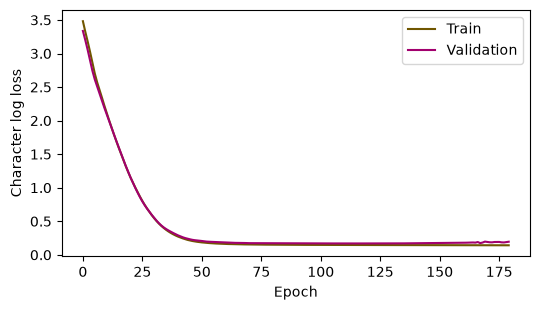

In [2]:
class CharacterModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(chars), 16, padding_idx=0)
        self.recurrent = nn.GRU(16, 32, batch_first=True)
        self.head = nn.Linear(32, len(chars))

    def forward(self, ids):
        features, _ = self.recurrent(self.embedding(ids))
        return self.head(features)

model = CharacterModel()
optimizer = torch.optim.Adam(model.parameters(), lr=0.015)
def log_loss(x, y):
    return nn.functional.cross_entropy(model(x).reshape(-1, len(chars)),
                                        y.reshape(-1), ignore_index=0)

history, best, checkpoint = [], float('inf'), None
for epoch in range(180):
    model.train()
    optimizer.zero_grad()
    loss = log_loss(Xtr, Ytr)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    model.eval()
    with torch.no_grad():
        validation = log_loss(Xva, Yva).item()
    history.append((loss.item(), validation))
    if validation < best:
        best, checkpoint = validation, copy.deepcopy(model.state_dict())
model.load_state_dict(checkpoint)
print('Best validation log loss:', round(best, 3))
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(np.asarray(history)[:, 0], label='Train', color='#705600')
ax.plot(np.asarray(history)[:, 1], label='Validation', color='#a2006e')
ax.set(xlabel='Epoch', ylabel='Character log loss')
ax.legend()
plt.tight_layout()
plt.show()

Gradient clipping limits the gradient norm; it does not change the data split or turn a poor model into a valid estimator. The checkpoint is selected by validation loss, and only then evaluated on test text.

## 6.3 · Evaluate likelihood against a simple baseline

In [3]:
counts = torch.bincount(Ytr[Ytr != 0], minlength=len(chars)).float() + 1
unigram = counts / counts.sum()
with torch.no_grad():
    neural_loss = log_loss(Xte, Yte).item()
    baseline_loss = -torch.log(unigram[Yte[Yte != 0]]).mean().item()
print(f'Unigram test loss: {baseline_loss:.3f}')
print(f'Neural test loss: {neural_loss:.3f}')
print(f'Character perplexity: {np.exp(neural_loss):.3f}')

Unigram test loss: 2.879
Neural test loss: 0.155
Character perplexity: 1.168


Perplexity is the exponential of mean token log loss. It is comparable here because both systems use the same alphabet and test targets. It is not directly comparable with a subword model's perplexity. A low score on this grammar does not establish factual accuracy, useful reasoning, or performance under a different language distribution.

## 6.4 · Decoding changes the sampling distribution

Temperature $T>0$ maps logits $z_j$ to probabilities proportional to $\exp(z_j/T)$. Top-k retains the k largest logits. Nucleus (top-p) sampling retains the smallest descending-probability prefix whose total mass reaches p, then renormalizes. We apply temperature, then top-k if requested, then top-p. Specifying this order matters when combining filters.

In [4]:
def decoding_probabilities(logits, temperature=1.0, top_k=None, top_p=1.0):
    if temperature <= 0 or not 0 < top_p <= 1:
        raise ValueError('Require temperature > 0 and 0 < top_p <= 1')
    z = logits.clone() / temperature
    z[0] = -torch.inf                 # never generate padding
    z[char_id['^']] = -torch.inf       # no new beginning marker
    if top_k is not None:
        if top_k < 1:
            raise ValueError('top_k must be positive')
        keep = torch.topk(z, min(top_k, len(z))).indices
        filtered = torch.full_like(z, -torch.inf)
        filtered[keep] = z[keep]
        z = filtered
    probabilities = torch.softmax(z, dim=-1)
    sorted_p, sorted_ids = torch.sort(probabilities, descending=True)
    # Keep the token that first crosses the requested cumulative mass.
    remove = sorted_p.cumsum(0) - sorted_p >= top_p
    probabilities[sorted_ids[remove]] = 0
    return probabilities / probabilities.sum()

@torch.no_grad()
def generate(prompt='the ', seed=1, greedy=False, **settings):
    model.eval()
    ids = [char_id[c] for c in '^' + prompt]
    generator = torch.Generator().manual_seed(seed)
    for _ in range(60):
        logits = model(torch.tensor([ids]))[0, -1]
        probabilities = decoding_probabilities(logits, **settings)
        next_id = int(probabilities.argmax()) if greedy else int(
            torch.multinomial(probabilities, 1, generator=generator))
        if chars[next_id] == '\n':
            break
        ids.append(next_id)
    return ''.join(chars[i] for i in ids[1:])

print('Greedy:', generate(greedy=True))
for temperature in [0.6, 1.0, 1.4]:
    for seed in [1, 2]:
        print(temperature, seed, generate(seed=seed, temperature=temperature, top_p=0.95))

Greedy: the agent learns patterns.
0.6 1 the network explains data.
0.6 2 the network learns uncertainty.
1.0 1 the network explains data.
1.0 2 the network learns uncertainty.
1.4 1 the network explains data.
1.4 2 the network learns uncertainty.


Read the generated strings, including malformed ones. Higher sampling entropy does not imply more useful diversity. Greedy decoding optimizes a local choice and need not find the globally most probable sequence. Sampling settings should be selected for a specified use case on development prompts, then evaluated on new prompts and repeated seeds.

## 6.5 · Prompting versus parameter estimation

A prompt changes the conditioning sequence while leaving fitted weights fixed. Examples in a prompt can demonstrate a pattern, but the ordinary inference call does not invoke the optimizer. Our tiny grammar model was never trained to follow instructions, so asking it to “explain Bayes' theorem” is a distribution-shift experiment, not a fair instruction-following test.

In [5]:
before = {name: value.detach().clone() for name, value in model.named_parameters()}
print('In-domain prefix:', generate(prompt='the agent '))
print('Out-of-domain prefix:', generate(prompt='explain '))
assert all(torch.equal(before[name], value) for name, value in model.named_parameters())
print('Generation left all model parameters unchanged.')

In-domain prefix: the agent learns data.
Out-of-domain prefix: explain studies patterns.
Generation left all model parameters unchanged.


Pretraining estimates a broad conditional model. Supervised instruction tuning changes parameters using instruction/response examples. Retrieval supplies external context. A system can combine all three. None is a substitute for checking whether the output answers the intended question using valid evidence.

## 6.6 · Exercises and worked solutions

1. **Teacher forcing:** why can the training loss be small while generated sequences drift? **Solution:** training conditions on observed prefixes; generation conditions on the model's own earlier samples. A locally plausible mistake can move later inputs away from the training distribution.
2. **Nucleus filter:** for probabilities $(0.5,0.3,0.2)$ and $p=0.6$, what survives? **Solution:** the first two tokens, because their cumulative mass first exceeds 0.6. Renormalized probabilities are $(0.625,0.375,0)$.
3. **Temperature:** show that the log odds between two tokens become $(z_i-z_j)/T$. **Solution:** take the logarithm of the ratio of their softmax probabilities; the normalization cancels. Decreasing positive temperature magnifies existing log-odds differences.
4. **Test protocol:** why not select temperature by reporting the best of 100 test generations? **Solution:** selection uses the test outcomes and changes the procedure being evaluated. Fix the selection rule on development prompts and evaluate its full distribution, including failed samples.
5. **Loss unit:** when do token-averaged and sequence-averaged losses agree? **Solution:** they agree when sequence lengths are equal, or accidentally when the relevant weighted and unweighted averages coincide. With varying lengths they generally estimate different targets.

## 6.7 · Further reading and transition

The official [PyTorch recurrent-layer documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html) describes the GRU used here. The [transformer paper](https://arxiv.org/abs/1706.03762) provides an alternative conditional architecture. Next, [Chapter 7](https://chikuang.github.io/teaching/genai/chapters/07-latent-variable-models.html) constructs distributions through latent variables instead of a token-by-token factorization.